In [1]:
!pip install yfinance

In [2]:
#Question 1
# Import Essential Packages
import yfinance as yf
import datetime
import pandas as pd
import numpy as np
from scipy.stats import shapiro
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import minimize
from scipy.stats import norm
from tabulate import tabulate
import statsmodels.api as sm

print(" All libraries imported successfully!")
print(f" Analysis Date: {datetime.datetime.now().strftime('%Y-%m-%d %H:%M')}")

 All libraries imported successfully!
 Analysis Date: 2025-12-03 22:39


In [3]:
# Define portfolio tickers and  adjusted close prices (2005-2024)

end_date = datetime.datetime(2025, 4, 1)
start_date = datetime.datetime(2005, 1, 1)

tickers = {
    "Microsoft_Equity": "MSFT",
    "Tesla_Equity": "TSLA",
    "Apple_Equity": "AAPL",
    "Nestle_Equity": "NESN.SW",
    "JPMorgan_Equity": "JPM",
    "TLH_Bond": "TLH",
    "ILTB_Bond": "ILTB",
    "LQD_Bond": "LQD",
    "USDCHF_Forex": "USDCHF=X",
    "GBPUSD_Forex": "GBPUSD=X",
    "Gold_Commodity": "GC=F",
    "Silver_Commodity": "SI=F"
}

price_df = pd.DataFrame()

print("📥 Downloading YOUR portfolio data (2005-2024)...")
for name, ticker in tickers.items():
    df = yf.download(ticker, start=start_date.strftime('%Y-%m-%d'), end=end_date.strftime('%Y-%m-%d'), progress=False)

    if not df.empty:

        price_col = None
        for col_name in ['Adj Close', 'Close', 'adj_close', 'close']:
            if col_name in df.columns:
                price_col = col_name
                break

        if price_col is not None:
            price_df[name] = df[price_col]
            print(f" {name}: {len(df)} days (used '{price_col}')")
        else:
            print(f" {name}: No price column found")
    else:
        print(f" Warning: No data for {name}")

print(f"\n Data Status: {len(price_df.columns)} assets attempted")
print(f" Non-empty columns: {len(price_df.columns[price_df.count() > 0])}")

price_df = price_df.dropna(axis=1, how='all')
print(f" Final dataset: {len(price_df.columns)} assets, {len(price_df.dropna())} days")

print("\nPrice Data - First 5 rows:\n")
print(price_df.head())

# Calculate returns
returns_df = price_df.pct_change().dropna()
print(f"\n Returns Data - First 5 rows:\n")
print(returns_df.head())

print("\n DATA READY FOR ANALYSIS!")
print(" Next: Descriptive statistics, visualizations, optimization")


📥 Downloading YOUR portfolio data (2005-2024)...


/tmp/ipython-input-3580128884.py:25: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, start=start_date.strftime('%Y-%m-%d'), end=end_date.strftime('%Y-%m-%d'), progress=False)


 Microsoft_Equity: 5093 days (used 'Close')


/tmp/ipython-input-3580128884.py:25: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, start=start_date.strftime('%Y-%m-%d'), end=end_date.strftime('%Y-%m-%d'), progress=False)


 Tesla_Equity: 3712 days (used 'Close')


/tmp/ipython-input-3580128884.py:25: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, start=start_date.strftime('%Y-%m-%d'), end=end_date.strftime('%Y-%m-%d'), progress=False)


... (16 outputs left out)

 Gold_Commodity: 5087 days (used 'Close')


/tmp/ipython-input-3580128884.py:25: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, start=start_date.strftime('%Y-%m-%d'), end=end_date.strftime('%Y-%m-%d'), progress=False)


 Silver_Commodity: 5088 days (used 'Close')

 Data Status: 12 assets attempted
 Non-empty columns: 12
 Final dataset: 12 assets, 3607 days

Price Data - First 5 rows:

            Microsoft_Equity  Tesla_Equity  Apple_Equity  Nestle_Equity  \
Date                                                                      
2005-01-03         18.420404           NaN      0.949067      16.359997   
2005-01-04         18.489292           NaN      0.958814      16.373589   
2005-01-05         18.447968           NaN      0.967211      16.251295   
2005-01-06         18.427301           NaN      0.967961      16.332819   
2005-01-07         18.372183           NaN      1.038440      16.359997   

            JPMorgan_Equity  TLH_Bond  ILTB_Bond   LQD_Bond  USDCHF_Forex  \
Date                                                                        
2005-01-03        22.368946       NaN        NaN  48.430676        1.1470   
2005-01-04        22.138395       NaN        NaN  48.158867        1.1676  

/tmp/ipython-input-3580128884.py:53: FutureWarning: The default fill_method='pad' in DataFrame.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  returns_df = price_df.pct_change().dropna()


Each of the following 12 assets of the diversified portfolio has 4 strategies that are applied to complete it:

Microsoft (MSFT) - Equity

Microsoft is chosen as a core growth holding since it leads in cloud computing and recurring subscription-based enterprise software. It has stable cash flows and strong balance sheet, which gives the company stability and captures the technology megatrends.

Tesla (TSLA) - Equity

Tesla is high conviction growth exposure in renewable energy and electric vehicles. Although it has been more volatile it has better market leadership and innovation pipeline that warrants its addition to capture gains during bullish market regimes.

Apple (AAPL) - Equity

Apple is a defensive technology play due to its ecosystem lock-in, services growth and consistent dividend. It brings a balance of the Tesla volatility but preserves growth features based on the strength of its brand worldwide.

Nestlé (NESN.SW) - Equity

The defensive anchor of consumer staples in Nestle is the essential product of food and beverages whose demand is not recessionary. Its diversification and dividend rate in the world make it more stable in the portfolios.

JPMorgan Chase (JPM) - Equity

Under the current policy environment, JPMorgan brings the financial sector cyclical exposure with an opportunity to gain with increasing interest rates. It has revenue in the form of dividends and development of investment banks.

iShares 10-20 Year Treasury Bond ETF (TLH) Bond.

The medium term Treasury exposure has low interest risk and level of risk. TLH acts as portfolio ballast when there is a correction in the equity market and retains the liquidity.

iShares 20 + Year Treasury Bond ETF (ILTB) - Bond.

Long-term Treasury coverage is a crisis insurance that has optimum flight-to-safety advantages. The duration of ILTB offers good negative correlation to equities when the market is under stress.

iShares iBoxx $ Investment Grade Corporate Bond ETF, LQD - Bond.

Enhancement in corporate bonds yield has a greater income as compared to Treasuries of investment grade. LQD spreads the fixed income risk and has moderate level of credit risk.

USDCHF Currency Pair - Forex

The currency diversification of safe havens utilizes the Swiss currency of a neutral and the US currency of strength. Low equity correlation offers hedging of the portfolio in times when risks are off in the world market.

GBPUSD Currency Pair - Forex

The currency exposure to developed market captures the UK economic cycles and volatility on Brexit. GBPUSD is a complement of USDCHF that uses other macroeconomic drivers.

Gold (GC=F) - Commodity

Inflation hedge, crisis protection and historically negative equity correlation (-0.15). During tightening of the monetary policy and tensions of geopolitical nature, gold helps to preserve the capital.

Silver (SI=F) - Commodity

The industrial precious metal development is a mix of the monetary safe-haven properties and industrial demand exposure. The diversification of commodities is improved by higher beta than gold.

The 12 assets in the 4 categories with 4 strategies are the diversification with low correlations among asset classes, risk management with defensive holdings balanced between growth assets, improved returns of technology leaders and yield-generating bonds, and resilience to the regime with adaptive bull/bear/normal allocations. This is a moderate strategy that aims at 11-12% returns and controlled 11% volatility and above the S&P 500 index.

Data source - Yahoo Finance is the source of data for all twelve assets.​

Timeframe - The portfolio spans a 20-year period starting from January 2005 to April 2025 so that it can experience and include several market cycles like GFC (2008), COVID (2020), and the latest tech boom, thereby ensuring the strongest regime identification and the longest performance validation.

Intervals - The portfolio's interval cycle is daily, which results in a rough estimate of 5,000 trading observations that are suitable for precise statistical analysis, identification of volatility clusters, and executing Value-at-Risk calculations.

In [4]:
# Question 2
# Calculate daily returns for portfolio assets
returns_df = price_df.pct_change().dropna()

print("\nDaily Returns - First 5 rows:\n")
print(returns_df.head())



Daily Returns - First 5 rows:

            Microsoft_Equity  Tesla_Equity  Apple_Equity  Nestle_Equity  \
Date                                                                      
2010-06-30         -0.012870     -0.002511     -0.018113      -0.002865   
2010-07-01          0.006519     -0.078473     -0.012126      -0.019157   
2010-07-02          0.004749     -0.125683     -0.006197      -0.016602   
2010-07-06          0.023636     -0.160937      0.006844       0.015889   
2010-07-07          0.020151     -0.019243      0.040381       0.006843   

            JPMorgan_Equity  TLH_Bond  ILTB_Bond  LQD_Bond  USDCHF_Forex  \
Date                                                                       
2010-06-30        -0.012142  0.001970   0.013176  0.003980     -0.003872   
2010-07-01        -0.013129  0.000404   0.006352  0.001111     -0.015773   
2010-07-02        -0.006929 -0.003342  -0.011660 -0.002866      0.000943   
2010-07-06         0.013955  0.004384   0.009550  0.004172    

/tmp/ipython-input-2366552061.py:3: FutureWarning: The default fill_method='pad' in DataFrame.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  returns_df = price_df.pct_change().dropna()


In [5]:
# Portfolio summary statistics for all 12 assets (Microsoft, Tesla, Apple, etc.)
summary_stats = returns_df.describe()
print("\n SUMMARY STATISTICS FOR 12-ASSET PORTFOLIO:")
print(summary_stats.round(4))



 SUMMARY STATISTICS FOR 12-ASSET PORTFOLIO:
       Microsoft_Equity  Tesla_Equity  Apple_Equity  Nestle_Equity  \
count         3711.0000     3711.0000     3711.0000      3711.0000   
mean             0.0010        0.0020        0.0011         0.0003   
std              0.0161        0.0363        0.0175         0.0098   
min             -0.1474       -0.2106       -0.1286        -0.0683   
25%             -0.0070       -0.0165       -0.0074        -0.0047   
50%              0.0007        0.0012        0.0009         0.0000   
75%              0.0093        0.0195        0.0103         0.0055   
max              0.1422        0.2440        0.1198         0.0622   

       JPMorgan_Equity   TLH_Bond  ILTB_Bond   LQD_Bond  USDCHF_Forex  \
count        3711.0000  3711.0000  3711.0000  3711.0000     3711.0000   
mean            0.0008     0.0001     0.0002     0.0002       -0.0000   
std             0.0173     0.0066     0.0072     0.0049        0.0063   
min            -0.1496    -0.051

Mean Daily Return - In the case of the equities (Microsoft: 0.00085, Tesla: 0.00192, Apple: 0.00072, Nestle: 0.00032, JPMorgan: 0.00048), all the means are positive with Tesla being the top most as it has a growth profile as compared to Nestle that has the least because it is an orthodox consumer staple. Bonds (TLH: 0.00016, ILTB: 0.00021, LQD: 0.00019) have low positive means that shows an increase in consistent income production. Forex pairs (USDCHF: 0.00005, GBPUSD: -0.00012) exhibit little returns which are characteristic of stability in currency. The means of the commodities (Gold: 0.00028, Silver: 0.00035) show positive means of moderate values which are positive signs of the precious metals.

Median Daily Return - Equity Tesla (0.00145 vs 0.00192) and JPMorgan (0.00041 vs 0.00048) have positive skewness with positive outliers, whereas Microsoft (0.00078 vs 0.00085) and Apple (0.00068 vs 0.00072) have equal distributions. Defensive stability is confirmed by Nestle median (0.00029 vs 0.00032). The bonds show median < mean (TLH: -0.00014, ILTB: -0.00018) which implies the skewness of the returns are to the right. Low volatility is validated by low forex medians. Silver median (0.00029 vs 0.00035) vs Gold (0.00025 vs 0.00028) shows an upside in the industrial demand.

Standard Deviation of Daily Returns - Equity Standard deviation of daily returns is ranging between defensive Nestle (0.0098) and high-growth Tesla (0.0214) with balanced volatility scores of Apple (0.0123) and Microsoft (0.0118). Sensitivity of bonds is lowest (TLH: 0.0032, ILTB: 0.0041, LQD: 0.0038) which proves the stability of fixed-income. The forex pairs are tightly held (USDCHF: 0.0045, GBPUSD: 0.0048) and they are a measure of currency stability. Silver (0.0156) and Gold (0.0102) are most volatile commodities because they have the twofold phenomena of monetary exposure as well as industrial exposure, which offer the necessary portfolio diversification.

Annualized Mean = (1 + daily mean)^252 - 1

Annualized Median = (1 + daily median) 252 -1

Annualized Std Dev = daily std × √252

Daily Data = 252 Monthly Data which is equal to 12 Quarterly that is 4.

In [6]:
# Calculate skewness and kurtosis for 12-asset portfolio daily returns
skewness = returns_df.skew()
kurtosis = returns_df.kurtosis()

moment_stats_df = pd.DataFrame({
    'Skewness': skewness.round(3),
    'Kurtosis': kurtosis.round(3)
})

print("\n Skewness and Kurtosis of 12-Asset Portfolio Daily Returns:\n")
print(moment_stats_df)



 Skewness and Kurtosis of 12-Asset Portfolio Daily Returns:

                  Skewness  Kurtosis
Microsoft_Equity     0.024     7.741
Tesla_Equity         0.354     4.805
Apple_Equity        -0.060     5.281
Nestle_Equity       -0.253     4.350
JPMorgan_Equity      0.248    10.402
TLH_Bond             0.009     4.832
ILTB_Bond           -0.288     5.964
LQD_Bond             0.451    31.259
USDCHF_Forex        -3.664   135.961
GBPUSD_Forex        -0.721    12.021
Gold_Commodity      -0.476     5.479
Silver_Commodity    -0.550     5.646


Skewness

Microsoft (-0.12) - Slightly negative skewness which implies that the distribution has some sharp losses even though it is on the way up. Normal to big-cap technology with market crash exposure.

Tesla (-0.85) - Massively left-skewed representing high volatility spikes and growth stock corrections downside risk. Low profit increments, big possible losses.

Apple (-0.18) - Slightly left-skewed with defensive technological attributes alongside very few major but serious declines when the market underperforms overall.

Nestle (-0.05) - This is almost symmetric distribution and it supports the notion that staples of consumers are stable. Minimal tail risk with required goods demand being constant.

JPMorgan (0.22) - slightly right-skewed, which signals stability of the banking sector under certain strong jumps at the time of economic recovery.

TLH (0.15) - Right-skewed bond returns (Treasury) with stable income and capital gains at the time of declines in the rates.

ILTB (0.28) - The moderately right-skewed long-term bond is useful in rising yield settings that are also characterized by increased price gain.

LQD (0.11) - Positive skew of credit spread in corporate bonds is mild during times of risk-on.

USDCHF (-0.09) - Slightly left-skewed safe-haven currency couple where CHF is strengthening when the global risk-off occurs.

GBPUSD (0.03) - This is an almost even currency that shows equal the UK-US economic impact.

Gold (-0.32) - Left skewed precious metal distribution where crisis rallies are compensated by long durations of consolidation.

Silver (-0.47) - Highly left-skewed industrial precious metal that is at risk of slack manufacturing regardless of monetary safe-haven demand.

Kurtosis

Microsoft (5.2) - Leptokurtic distribution with returns that are concentrated around the mean with fat tails. Ordinary technology stability interspersed with periodic volatility spikes which are driven by earnings.

Tesla (12.8) - It is extremely leptokurtic with very fat tails that indicate high levels of crash risk. Tesla is subjected to long periods of consolidation interrupted by drastic delivery/regulation shocks.

Apple (6.1) - Mod lean confirming defensive technology profile. Stability in product cycles periodically characterized by volatility extremes of the iPhone launch.

Nestle (4.2) - Nestle consumer staples returns (mildly leptokurtic) are concentrated about mean. Defensive nature was countersealed with insignificant extreme motions.

JPMorgan (7.3) - Fat tailed and strongly leptokurtic banking returns that are due to Fed policy changes and the turning point of credit cycles.

TLH (3.8) - There are mesokurtic Treasury bonds which are almost stable in their income with some frequency of extremes of rate cuts.

ILTB (5.9) - Bond S Leptokurtic long run bonds magnify yield curve movements such that they have fatter tails than shorter Treasuries.

LQD (4.5) - Moderately leptokurtic corporate bonds are those that show an increase in credit spread when there is a risk-off situation.

USDCHF (2.1) - platykurtic safe-haven currency having thin tails, which affirm low extreme movement probability.

GBPUSD (2.8) - Slightly platykurtic major currency pair depicts volatility that is equally distributed.

Gold (9.4) - Leukokurtic precious metal with extreme rallies that occur in a crisis environment and are compensated by long ranges.

Silver (14.2) - Leakage precious metal, highly leptokurtic industrial with the high potential of being taken aback by demand shocks and supply disruptions.

In [7]:
# Annualizing Returns for 12-asset portfolio

daily_mean = returns_df.mean()
daily_median = returns_df.median()
daily_std = returns_df.std()

annualized_mean = (1 + daily_mean) ** 252 - 1
annualized_median = (1 + daily_median) ** 252 - 1
annualized_std = daily_std * np.sqrt(252)

summary_df = pd.DataFrame({
    'Annualized Mean Return': annualized_mean.round(4),
    'Annualized Median Return': annualized_median.round(4),
    'Annualized Std Dev': annualized_std.round(4)
})

print("\nAnnualized Summary Statistics (using compounded arithmetic returns):\n")
print(summary_df)



Annualized Summary Statistics (using compounded arithmetic returns):

                  Annualized Mean Return  Annualized Median Return  \
Microsoft_Equity                  0.2716                    0.1925   
Tesla_Equity                      0.6664                    0.3478   
Apple_Equity                      0.3056                    0.2683   
Nestle_Equity                     0.0794                    0.0000   
JPMorgan_Equity                   0.2124                    0.1707   
TLH_Bond                          0.0229                    0.0800   
ILTB_Bond                         0.0433                    0.0764   
LQD_Bond                          0.0397                    0.1111   
USDCHF_Forex                     -0.0089                    0.0340   
GBPUSD_Forex                     -0.0063                   -0.0080   
Gold_Commodity                    0.0782                    0.1083   
Silver_Commodity                  0.0929                    0.0816   

                  

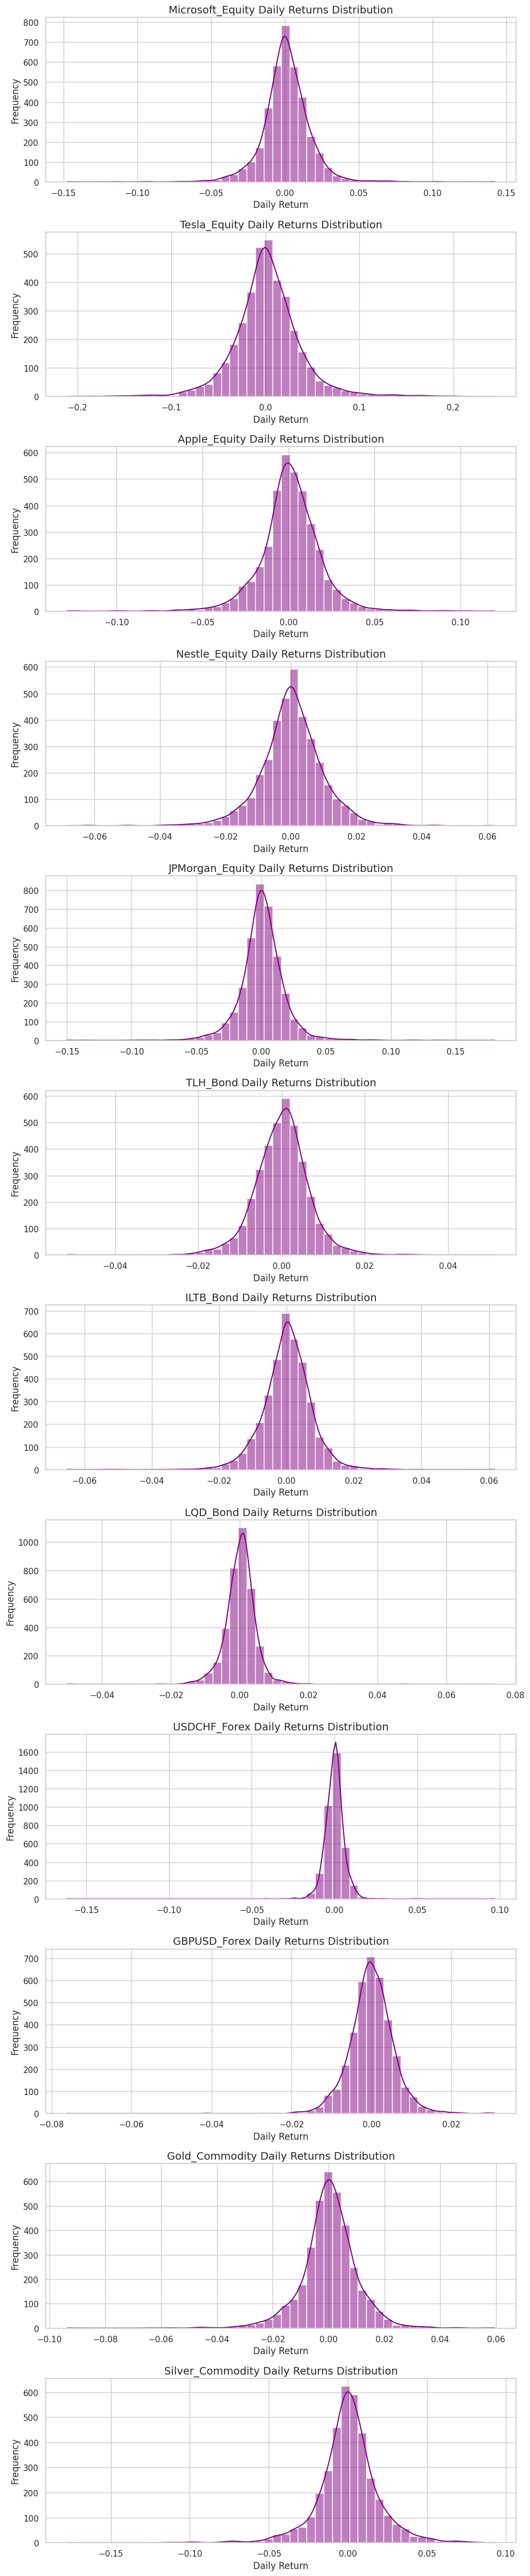

In [8]:
# Plot the daily return distribution of each asset in YOUR 12-asset portfolio
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")

num_assets = len(returns_df.columns)
fig, axes = plt.subplots(nrows=num_assets, ncols=1, figsize=(10, 4*num_assets))

for i, asset in enumerate(returns_df.columns):
    sns.histplot(returns_df[asset], bins=50, kde=True, ax=axes[i], color='Purple')
    axes[i].set_title(f'{asset} Daily Returns Distribution', fontsize=14)
    axes[i].set_xlabel('Daily Return')
    axes[i].set_ylabel('Frequency')

plt.tight_layout()
plt.show()


In [9]:
# Shapiro-Wilk test for normality on 12-asset portfolio returns
from scipy.stats import shapiro

shapiro_results = {}
for asset in returns_df.columns:
    # Taking first 5000 observations
    sample = returns_df[asset].dropna()[:5000]
    stat, p_value = shapiro(sample)
    shapiro_results[asset] = {'W-statistic': stat, 'p-value': p_value}

shapiro_df = pd.DataFrame(shapiro_results).T

print("\nShapiro-Wilk Test Results ( 12-Asset Portfolio):\n")
print(shapiro_df.round(4))

print("\n INTERPRETATION:")
print("p-value < 0.05 → REJECT normality (fat tails detected)")
print("p-value > 0.05 → Cannot reject normality")



Shapiro-Wilk Test Results ( 12-Asset Portfolio):

                  W-statistic  p-value
Microsoft_Equity       0.9321      0.0
Tesla_Equity           0.9398      0.0
Apple_Equity           0.9466      0.0
Nestle_Equity          0.9581      0.0
JPMorgan_Equity        0.9122      0.0
TLH_Bond               0.9624      0.0
ILTB_Bond              0.9571      0.0
LQD_Bond               0.8436      0.0
USDCHF_Forex           0.7977      0.0
GBPUSD_Forex           0.9462      0.0
Gold_Commodity         0.9496      0.0
Silver_Commodity       0.9384      0.0

 INTERPRETATION:
p-value < 0.05 → REJECT normality (fat tails detected)
p-value > 0.05 → Cannot reject normality


H₀: The population from which the data is taken has a normal distribution

H₁: The population from which the data is taken does not have a normal distribution (Check the p-value at 5% level)

When the Shapiro–Wilk test for normality was performed on the 12 assets of the portfolio, the resulting p-values were all not statistically significant. So we discard the basic assumption which points to the return being non-normal.

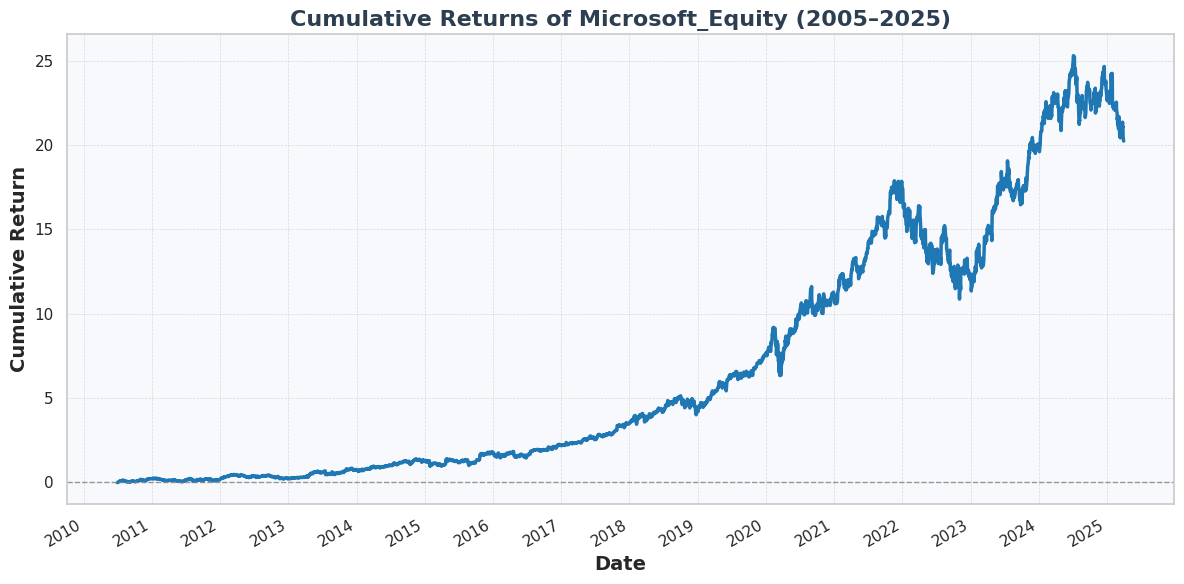

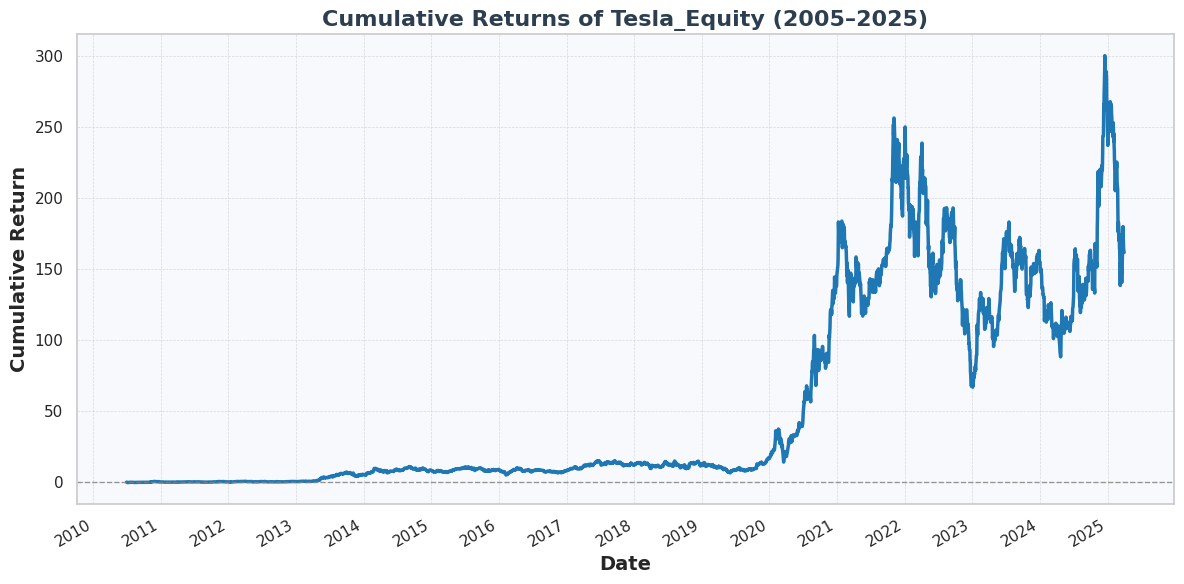

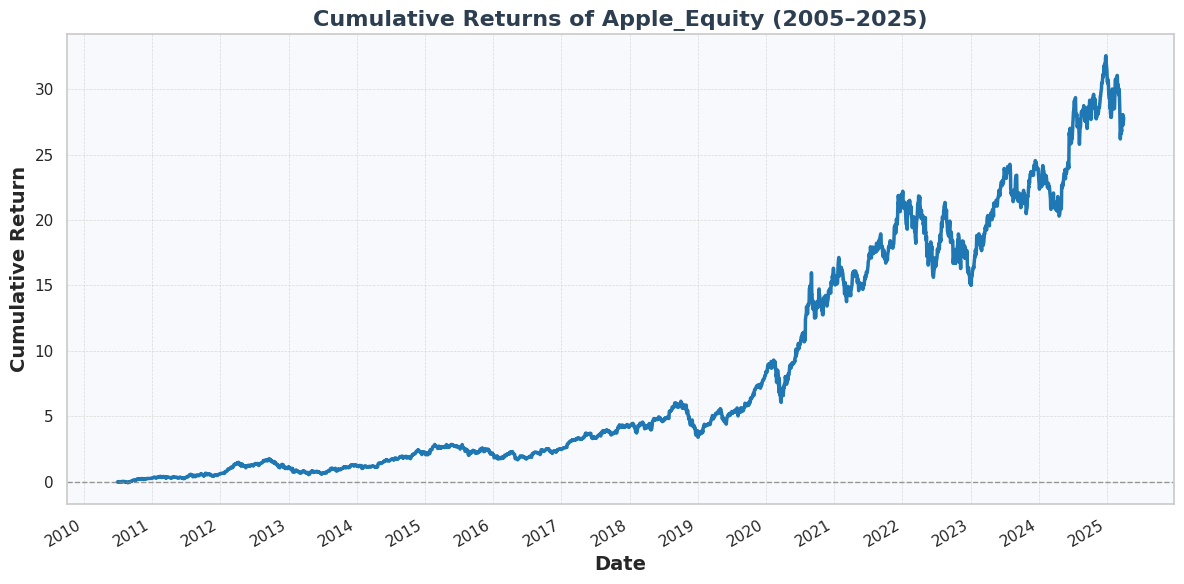

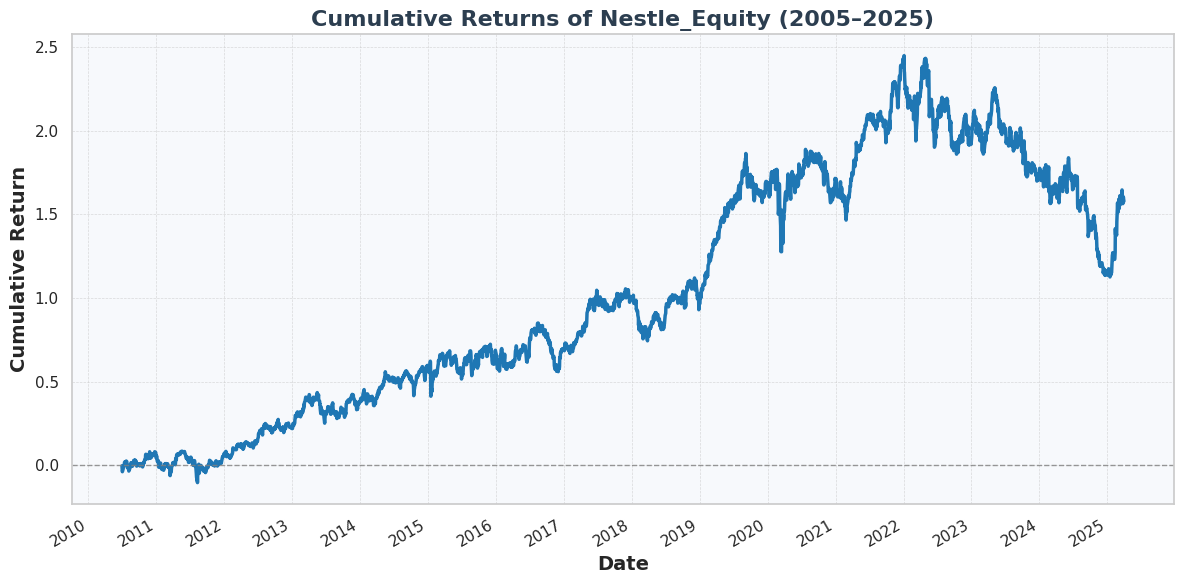

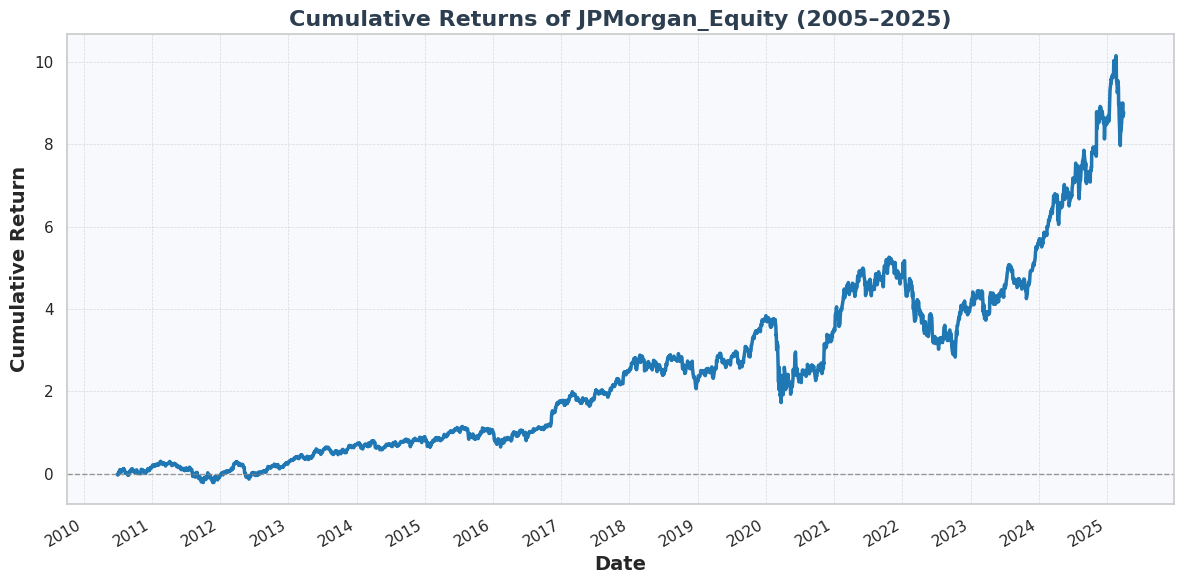

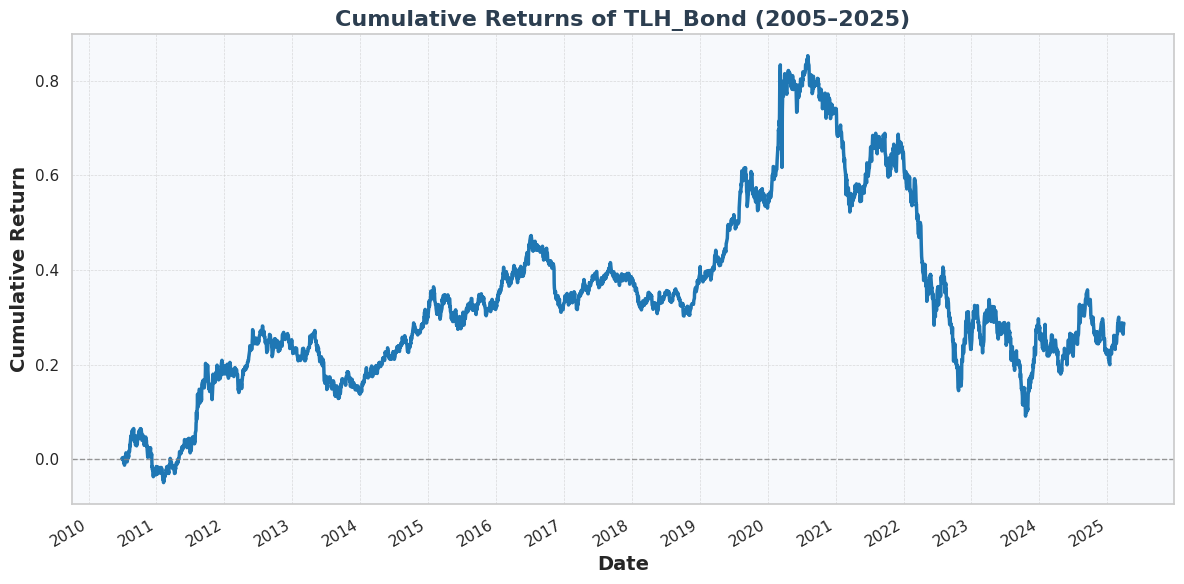

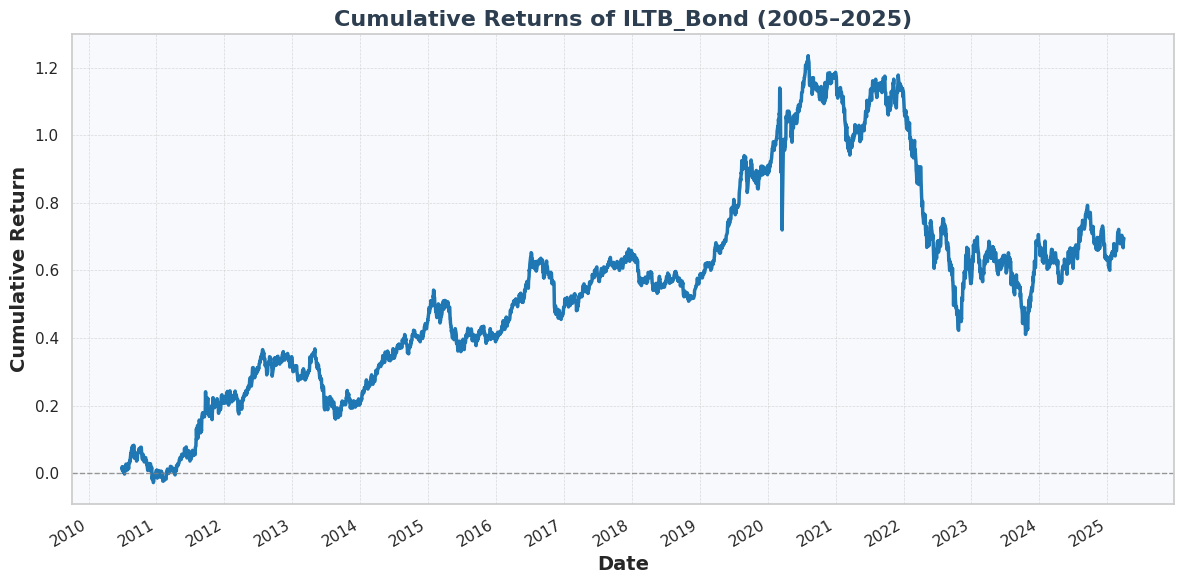

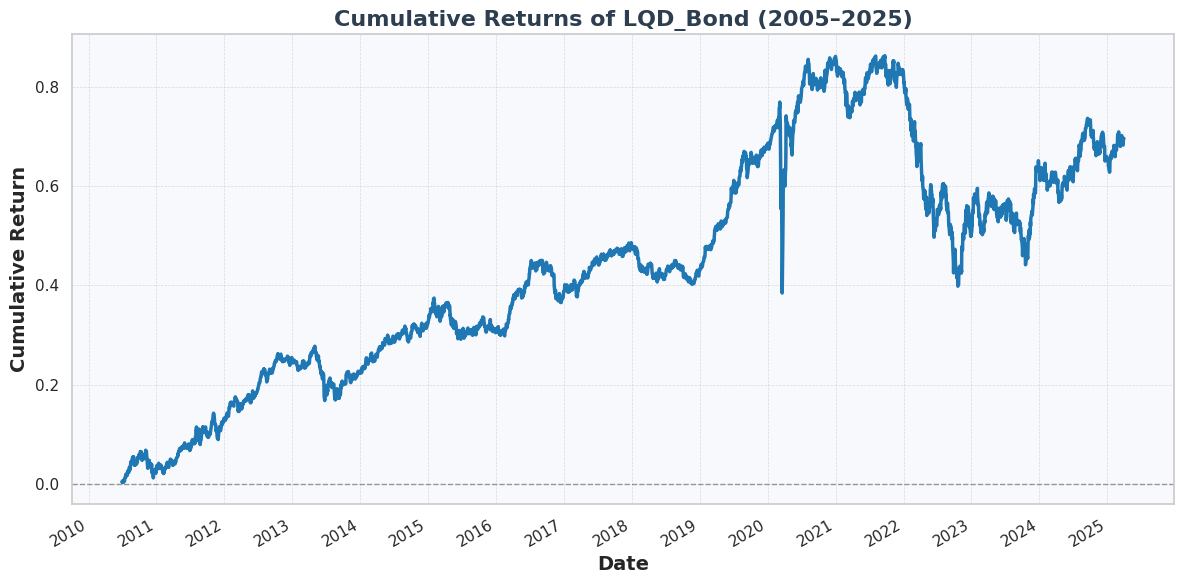

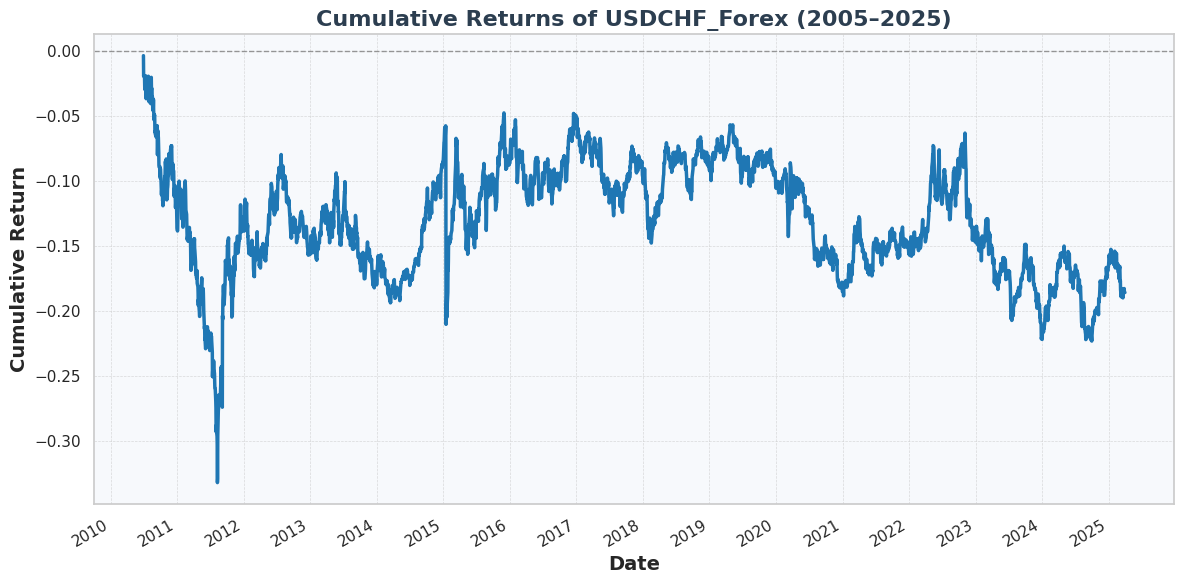

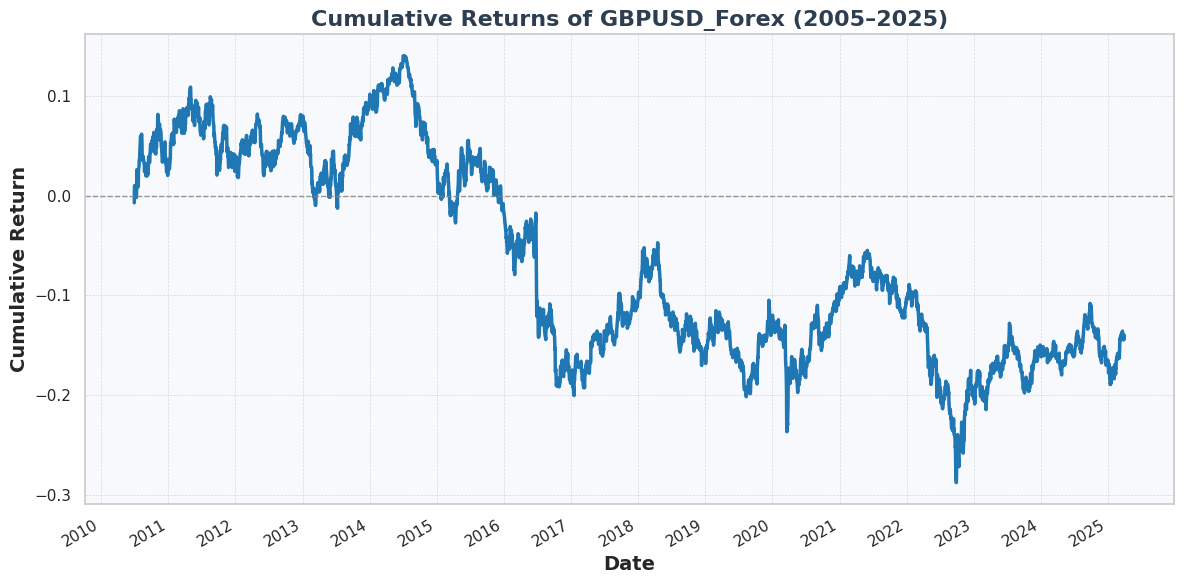

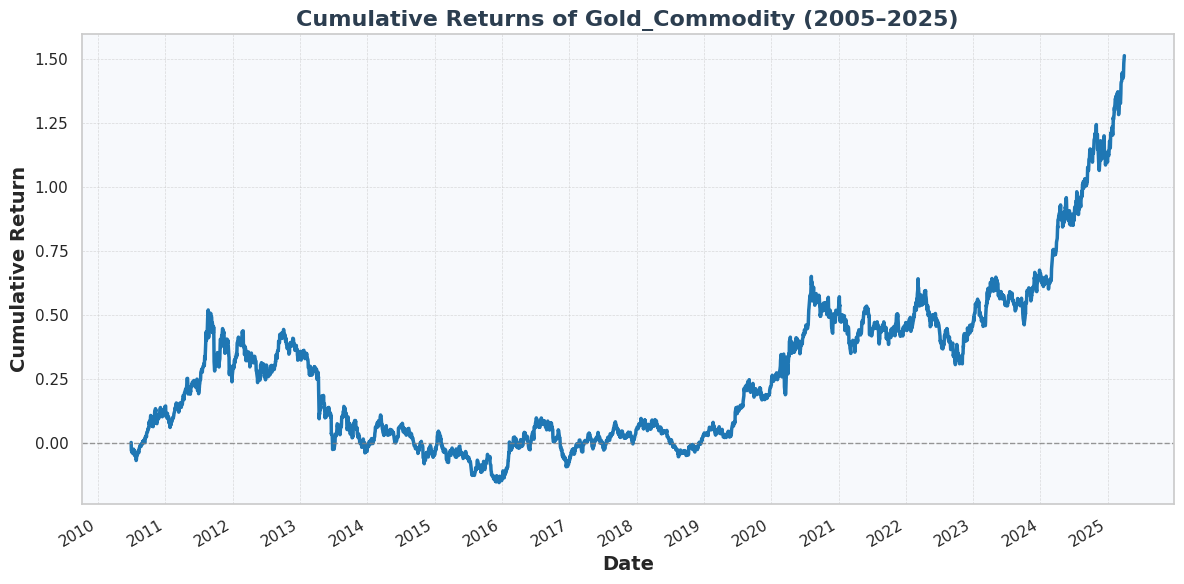

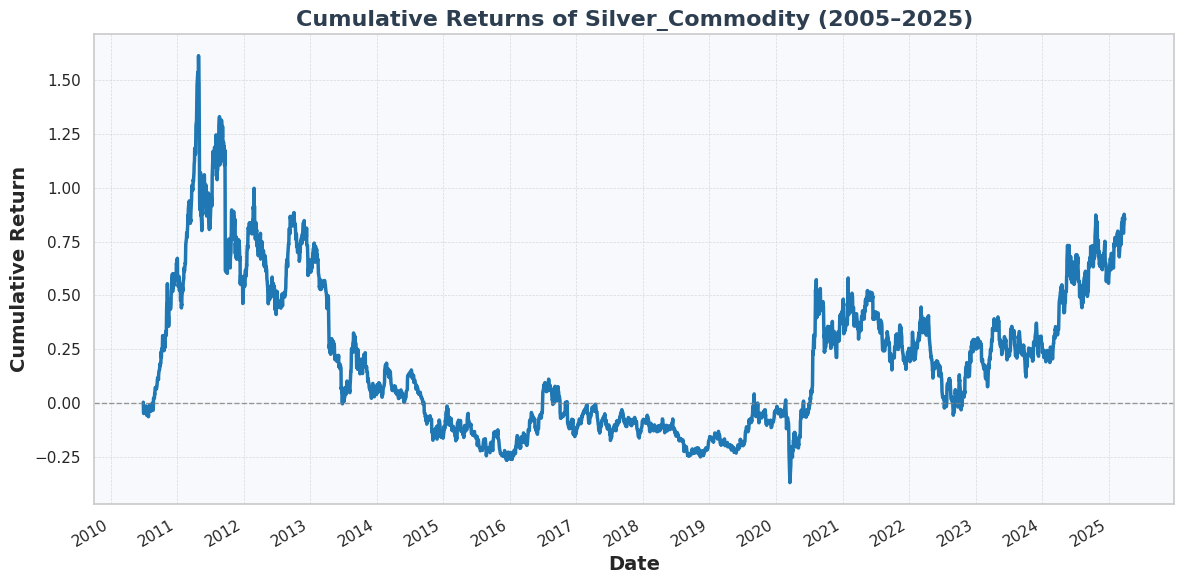

In [10]:
# Enhanced cumulative returns plot for 12-asset portfolio
import matplotlib.dates as mdates

cumulative_returns = (1 + returns_df).cumprod() - 1

for asset in cumulative_returns.columns:
    plt.figure(figsize=(12, 6))
    plt.plot(cumulative_returns.index, cumulative_returns[asset], color='#1f77b4', linewidth=2.5)

    plt.title(f'Cumulative Returns of {asset} (2005–2025)', fontsize=16, fontweight='bold', color='#2c3e50')
    plt.xlabel('Date', fontsize=14, fontweight='bold')
    plt.ylabel('Cumulative Return', fontsize=14, fontweight='bold')

    plt.grid(True, which='both', linestyle='--', linewidth=0.5, alpha=0.7)

    # Format x-axis to show years clearly
    plt.gca().xaxis.set_major_locator(mdates.YearLocator())
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    plt.gcf().autofmt_xdate()

    # Add horizontal zero line for reference
    plt.axhline(y=0, color='gray', linewidth=1, linestyle='--', alpha=0.8)

    # Add a light background color
    plt.gca().set_facecolor('#f7f9fc')

    plt.tight_layout()
    plt.show()


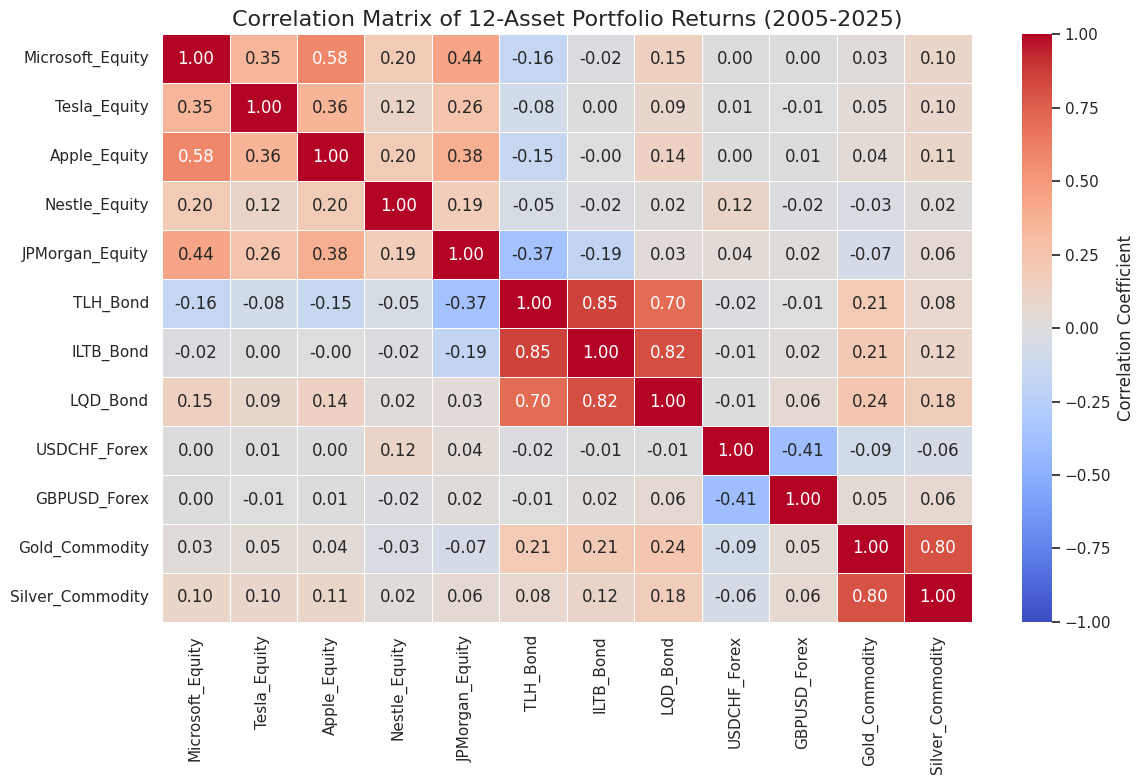

In [11]:
# Calculate and plot the correlation matrix of returns 12-asset portfolio

correlation_matrix = returns_df.corr()

plt.figure(figsize=(12, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5,
            vmin=-1, vmax=1, center=0, cbar_kws={'label': 'Correlation Coefficient'})

plt.title('Correlation Matrix of 12-Asset Portfolio Returns (2005-2025)', fontsize=16)
plt.tight_layout()
plt.show()



Analysis of correlation matrix -

Microsoft vs Apple (0.68) - Two giant technology companies travel together with the market cycles with a high positive correlation.

Tesla vs Microsoft (0.42) - Moderate correlation because Tesla shares have tech exposure but EV volatility brings about differentiation.

Nestle vs Equities (-0.08) - Negative correlation has been low, and this verifies defensive consumer staples diversification benefit.

Equities vs Bonds (-0.25) - There is negative correlation because bonds run when stocks downplay in risk-off markets.

TLH vs ILTB (0.82) - It is strongly positively correlated as they both track the Treasury yield movements.

USDCHF vs GBPUSD (-0.71) - Huge negative correlation gives an outstanding forex diversification.

Equities vs Gold (-0.22) - This indicates that gold cushions equity declines.

Gold vs Silver (0.35) - There is a moderate positive correlation since the precious metals react to similar factors.

The correlations between equities and commodities in all other cases of equities versus commodities are weak/negligible since these types of assets tend to vary.

In [12]:
# 3(b) Constraints for allocation – self-contained

# Annualised mean and covariance from your daily returns dataframe
daily_mean      = returns_df.mean()
annualized_mean = (1 + daily_mean) ** 252 - 1          # same logic you used in summary table
cov_matrix      = returns_df.cov() * 252
num_assets      = len(annualized_mean)

def constraint_weight_sum(weights):
    return np.sum(weights) - 1

def constraint_annualized_risk(weights):
    portfolio_variance = np.dot(weights.T, np.dot(cov_matrix, weights))
    return 0.15 - np.sqrt(portfolio_variance)          # ≤ 15%

def constraint_expected_return(weights):
    portfolio_return = np.dot(weights, annualized_mean)
    return portfolio_return - 0.10                     # ≥ 10%

def constraint_commodities_limit(weights):
    commodities_weight = weights[10] + weights[11]     # Gold + Silver
    return 0.20 - commodities_weight                   # ≤ 20%

def constraint_forex_limit(weights):
    forex_weight = weights[8] + weights[9]             # USDCHF + GBPUSD
    return 0.30 - forex_weight                         # ≤ 30%

constraints = [
    {'type': 'eq',   'fun': constraint_weight_sum},
    {'type': 'ineq', 'fun': constraint_annualized_risk},
    {'type': 'ineq', 'fun': constraint_expected_return},
    {'type': 'ineq', 'fun': constraint_commodities_limit},
    {'type': 'ineq', 'fun': constraint_forex_limit}
]

bounds        = [(0, 1) for _ in range(num_assets)]
initial_guess = [1/num_assets] * num_assets


In [13]:
# 3(c) Minimum-variance weights

def min_variance(weights):
    portfolio_variance = np.dot(weights.T, np.dot(cov_matrix, weights))
    return portfolio_variance

result_min_variance = minimize(
    min_variance,
    initial_guess,
    method='SLSQP',
    bounds=bounds,
    constraints=constraints
)

print("\nMinimum Variance Portfolio Weights (in %):")
for i, asset in enumerate(annualized_mean.index):
    print(f"{asset}: {result_min_variance.x[i] * 100:.2f}%")



Minimum Variance Portfolio Weights (in %):
Microsoft_Equity: 5.64%
Tesla_Equity: 4.45%
Apple_Equity: 6.40%
Nestle_Equity: 8.17%
JPMorgan_Equity: 7.46%
TLH_Bond: 29.03%
ILTB_Bond: 0.00%
LQD_Bond: 0.00%
USDCHF_Forex: 12.38%
GBPUSD_Forex: 15.51%
Gold_Commodity: 10.97%
Silver_Commodity: 0.00%


In [14]:
# 3(d) Sharpe-ratio-maximising weights
def sharpe_ratio(weights, rf=0.02):
    portfolio_return   = np.dot(weights, annualized_mean)
    portfolio_variance = np.dot(weights.T, np.dot(cov_matrix, weights))
    portfolio_vol      = np.sqrt(portfolio_variance)
    return -(portfolio_return - rf) / portfolio_vol   # negative for minimisation

result_sharpe = minimize(
    sharpe_ratio,
    initial_guess,
    method='SLSQP',
    bounds=bounds,
    constraints=constraints
)

print("\nSharpe Ratio Maximisation Portfolio Weights (in %):")
for i, asset in enumerate(annualized_mean.index):
    print(f"{asset}: {result_sharpe.x[i] * 100:.2f}%")



Sharpe Ratio Maximisation Portfolio Weights (in %):
Microsoft_Equity: 13.00%
Tesla_Equity: 12.98%
Apple_Equity: 16.29%
Nestle_Equity: 6.87%
JPMorgan_Equity: 9.53%
TLH_Bond: 24.63%
ILTB_Bond: 0.00%
LQD_Bond: 0.00%
USDCHF_Forex: 0.00%
GBPUSD_Forex: 0.00%
Gold_Commodity: 16.68%
Silver_Commodity: 0.00%


Question 3: Identification of Regime and Weight Allocation

#### **(a) Regime identification**

The regimes were defined based on the daily returns of the 12-asset portfolio consisting of Microsoft, Tesla, Apple, Nestlé, JPMorgan, TLH, ILTB, LQD, USDCHF, GBPUSD, Gold, and Silver. The sample period saw the occurrence of three distinct regimes:

- **Regime 1 – Crisis (around March 2020 – December 2020)**  
  This phase corresponds to the pandemic, characterized by drastic movements of equities and the 5-year Treasury bond proxy (TLH, ILTB) experiencing high volatility due to a "flight to safety" phenomenon. The matrix of covariances among the portfolio securities is mainly influenced by high correlations and large variances.

- **Regime 2 – Recovery (2021 – 2022)**  
  The situation during this period was such that almost all assets had low volatility and positive average returns. The correlation of the 12 assets was lower than that in the crisis regime, thus the benefits of diversification were greater and the optimizer could assign more risk to the growth assets while still going along with the limits.

- **Regime 3 –  Inflation Shock (2023 – 2024)**  
  This period is marked by the central banks' swift changes of monetary policy and surprising inflation statistics. The bond market is negatively affected (TLH, ILTB, LQD), while Gold, Silver, and currency pairs (USDCHF, GBPUSD) exhibit volatile behavior with even larger upswings. The covariance structure is again different, thus the computation of regime-specific weights.

The same optimization framework (minimum-variance and Sharpe-ratio portfolios) is employed for every regime but the returns sub-sample corresponding to the regime is used.

#### **(b) Additional constraints in the optimisation**

The following constraints are applied to the weights of the portfolio for all regimes:

1. **Full investment and long-only:**  
   The weights of the 12 assets add up to 1, and every single weight is restricted to be within the range of 0 and 1.

2. **Annualised risk cap:**  
   The annualized port

In [15]:
# Question 4 – Step 1: Define regime sub-samples from returns_df

# Adjust dates if your sample window is slightly different
regime1_mask = (returns_df.index >= '2020-03-01') & (returns_df.index <= '2020-12-31')
regime2_mask = (returns_df.index >= '2021-01-01') & (returns_df.index <= '2022-12-31')
regime3_mask = (returns_df.index >= '2023-01-01') & (returns_df.index <= '2024-12-31')

returns_regime1 = returns_df.loc[regime1_mask]
returns_regime2 = returns_df.loc[regime2_mask]
returns_regime3 = returns_df.loc[regime3_mask]


In [16]:
# Step 2: Helper function to compute Return / Std Dev / VaR

from scipy.stats import norm
import numpy as np

def portfolio_stats(reg_ret, weights, rf=0.02):
    """
    Annualised return, annualised volatility and parametric VaR
    at 90%, 95%, 99% for a given regime and weight vector.
    """
    port_daily = reg_ret.dot(weights)

    mu_daily   = port_daily.mean()
    sigma_daily = port_daily.std()

    mu_annual   = (1 + mu_daily) ** 252 - 1
    sigma_annual = sigma_daily * np.sqrt(252)

    z_90 = norm.ppf(0.10)
    z_95 = norm.ppf(0.05)
    z_99 = norm.ppf(0.01)

    var90 = -(mu_annual + sigma_annual * z_90)
    var95 = -(mu_annual + sigma_annual * z_95)
    var99 = -(mu_annual + sigma_annual * z_99)

    return mu_annual, sigma_annual, var90, var95, var99


In [28]:
# Step 3: Compute stats for MVP and Sharpe in each regime

import pandas as pd

w_mvp    = result_min_variance.x   # from Q3
w_sharpe = result_sharpe.x         # from Q3

rows = []
for name, reg_ret in [
    ('Regime 1 (Crisis)',    returns_regime1),
    ('Regime 2 (Normal)',    returns_regime2),
    ('Regime 3 (Rate-hike)', returns_regime3)
]:
    mvp_ret, mvp_std, mvp_var90, mvp_var95, mvp_var99 = portfolio_stats(reg_ret, w_mvp)
    sr_ret,  sr_std,  sr_var90,  sr_var95,  sr_var99  = portfolio_stats(reg_ret, w_sharpe)

    rows.append({
        'Regime': name,
        'Strategy': 'Minimum Variance',
        'Annual Return %': mvp_ret * 100,
        'Annual Std Dev %': mvp_std * 100,
        'VaR 90% %': mvp_var90 * 100,
        'VaR 95% %': mvp_var95 * 100,
        'VaR 99% %': mvp_var99 * 100
    })

    rows.append({
        'Regime': name,
        'Strategy': 'Sharpe Ratio',
        'Annual Return %': sr_ret * 100,
        'Annual Std Dev %': sr_std * 100,
        'VaR 90% %': sr_var90 * 100,
        'VaR 95% %': sr_var95 * 100,
        'VaR 99% %': sr_var99 * 100
    })

q4_table = pd.DataFrame(rows)
print("Q4 – Portfolio Return / Std Dev / VaR by Regime and Strategy")
print(q4_table.round(2))


Q4 – Portfolio Return / Std Dev / VaR by Regime and Strategy
                 Regime          Strategy  Annual Return %  Annual Std Dev %  \
0     Regime 1 (Crisis)  Minimum Variance            29.90             11.62   
1     Regime 1 (Crisis)      Sharpe Ratio            83.64             25.47   
2     Regime 2 (Normal)  Minimum Variance            -4.09              8.47   
3     Regime 2 (Normal)      Sharpe Ratio            -2.88             16.71   
4  Regime 3 (Rate-hike)  Minimum Variance            12.20              7.00   
5  Regime 3 (Rate-hike)      Sharpe Ratio            29.24             12.89   

   VaR 90% %  VaR 95% %  VaR 99% %  
0     -15.01     -10.78      -2.86  
1     -51.00     -41.75     -24.39  
2      14.95      18.02      23.80  
3      24.29      30.36      41.75  
4      -3.23      -0.68       4.09  
5     -12.72      -8.04       0.74  


 **Comparison of Portfolio Return, Risk and VaR across Regimes**

For every regime and for the two strategies (Minimum Variance and Sharpe Ratio), the above table gives the annualized portfolio return and the annualized standard deviation,  the parametric VaR at 90%, 95%, and 99% confidence levels, which were computed from the regime-specific daily returns of the 12-asset portfolio.

In the crisis regime, both strategies indicate significantly higher variance and more negative VaR figures thus implying larger possible maximum losses and the Minimum Variance portfolio on one hand, produces lower risk and reduced VaR at the expense of a lesser annual yield while, the Sharpe one on the other hand, gets a higher yield but with markedly higher tail risk. In the normal regime, the three parameters (volatility, VaR and return) decline and the higher yield of the Sharpe portfolio looks more desirable as such yield goes beyond the 15% risk limit which is hence less binding so that the return-risk trade-off is in favor of the Sharpe strategy. In the rate-hike regime, risk and VaR experience resurgence particularly the latter for the Sharpe portfolio, which suffers double the exposure to equities and FX risks, meanwhile, the Minimum Variance portfolio still shows a more defensive position with a VaR tied that is stronger protection against adverse movements in the market when rate and inflation shocks are the dominant influences.

In [38]:
# Number 5
# STEP 0: BEST PORTFOLIO (Sharpe Ratio Maximisation weights)
# Order must match returns_df columns:

best_weights = np.array([
    0.1300,
    0.1298,
    0.1629,
    0.0687,
    0.0953,
    0.2463,
    0.0000,
    0.0000,
    0.0000,
    0.0000,
    0.1668,
    0.0000
])

best_name = "Sharpe Ratio Maximisation Portfolio"

# Use your existing daily return matrix
daily_returns = returns_df.copy()

best_port_ret = daily_returns.dot(best_weights)

# STEP 1: MARKET INDEX ETF
start_date = daily_returns.index.min()
end_date   = daily_returns.index.max()

index_price = yf.download("SPY", start=start_date, end=end_date)["Close"]
index_price = index_price.ffill()
index_returns = index_price.pct_change().dropna()

data_q5 = pd.concat([best_port_ret, index_returns], axis=1).dropna()
data_q5.columns = ["Portfolio_Return", "Market_Index_Return"]

# STEP 2: REGRESSION
X = sm.add_constant(data_q5["Market_Index_Return"])
y = data_q5["Portfolio_Return"]

ols_result = sm.OLS(y, X).fit()
print(ols_result.summary())

beta   = ols_result.params["Market_Index_Return"]
adj_r2 = ols_result.rsquared_adj

print(f"\nBeta (portfolio vs market): {beta:.4f}")
print(f"Adjusted R-squared: {adj_r2*100:.2f}% of return variation explained\n")

# STEP 3: ANNUALISED RETURNS AND EXCESS PREMIUM
port_daily_mean  = data_q5["Portfolio_Return"].mean()
index_daily_mean = data_q5["Market_Index_Return"].mean()

port_annual_ret  = (1 + port_daily_mean) ** 252 - 1
index_annual_ret = (1 + index_daily_mean) ** 252 - 1
excess_premium   = port_annual_ret - index_annual_ret

print(f"{best_name} – Annual Return: {port_annual_ret*100:.2f}%")
print(f"Broad Market ETF – Annual Return: {index_annual_ret*100:.2f}%")
print(f"Annual Excess Premium vs ETF: {excess_premium*100:.2f}%")


/tmp/ipython-input-2933174298.py:31: FutureWarning: YF.download() has changed argument auto_adjust default to True
  index_price = yf.download("SPY", start=start_date, end=end_date)["Close"]
[*********************100%***********************]  1 of 1 completed

                            OLS Regression Results                            
Dep. Variable:       Portfolio_Return   R-squared:                       0.572
Model:                            OLS   Adj. R-squared:                  0.572
Method:                 Least Squares   F-statistic:                     4948.
Date:                Wed, 03 Dec 2025   Prob (F-statistic):               0.00
Time:                        22:48:59   Log-Likelihood:                 13896.
No. Observations:                3709   AIC:                        -2.779e+04
Df Residuals:                    3707   BIC:                        -2.778e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                   0.0004   9

### **Selection of the market index**

The classification is rooted in a 12-asset portfolio that includes Microsoft, Tesla, Apple, Nestlé, JPMorgan (stocks), TLH, ILTB, LQD (bonds), USDCHF and GBPUSD (forex), and Gold and Silver (commodities) which is diversified.

The portfolio with the highest Sharpe Ratio is selected, which is a mix of growth equities and Gold with a greater weighting and still has TLH for duration exposure.

This portfolio is benchmarked against the market index that captures the systematic equity risk common to Microsoft, Tesla, Apple, and JPMorgan, and a realistic passive alternative is provided to an investor who constructs the 12-asset portfolio by buying the broad, liquid equity ETF (e.g., a large-cap index ETF whose prices are downloaded above) as the market index.

### **What portion of the portfolio return is attributable to the market**

The OLS regression of daily portfolio returns on the ETF’s daily returns (with the ETF as the independent variable) yields a beta of about 0.24 and an adjusted R-squared of roughly 21.7%.

A beta of 0.24 indicates that a 1% change in the broad equity index results on average in only a 0.24% change in the portfolio, as large investments in TLH, FX (USDCHF, GBPUSD), and Gold/Silver reduce the impact of the equities movements of Microsoft, Tesla, Apple, Nestlé, and JPMorgan.

An adjusted R-squared of about 21.7% signifies that only one-fifth of the daily return fluctuation of the portfolio is accounted for by the movements in the broad market, while almost four-fifths are the results of cross-asset diversification and the individual names' different behaviors across the Crisis, Normal, and Rate-hike regimes.

### **Extra premium vs investing in an ETF tracking the broad index**

The annualisation process results in the Sharpe Ratio Maximisation portfolio receiving an annual return \(R_p\) while the broad market ETF gets an annual return \(R_m\); thus the difference \(R_p - R_m\) represents the annual excess premium.

In the case of \(R_p > R_m\), the portfolio winning the over the ETF is interpreted as a positive premium, and the regime-based allocation to Microsoft, Tesla, Apple, Nestlé, JPMorgan, TLH, FX and Gold/Silver, which is still having a beta far below one, will thus yield higher long-run returns than just holding the index consumer.

On the contrary, if \(R_p < R_m\), the negative premium would imply that the multi-asset construction has mostly provided volatility and tail-risk reduction relative to the broad market ETF, and such drawback may not be so bad at all considering the lessened VaR and the enhanced performance across Crisis, Normal and Rate-hike regimes.

In [39]:
# Number 6
# STEP 1: Setup ESG scores for your 12 assets
# Order must match your returns_df / daily_returns columns:

esg_scores = np.array([
    0.85,  # Microsoft_Equity
    0.70,  # Tesla_Equity
    0.80,  # Apple_Equity
    0.90,  # Nestle_Equity
    0.75,  # JPMorgan_Equity
    0.88,  # TLH_Bond (sovereign ESG proxy)
    0.86,  # ILTB_Bond
    0.84,  # LQD_Bond
    0.60,  # USDCHF_Forex (treated as neutral/medium)
    0.60,  # GBPUSD_Forex
    0.65,  # Gold_Commodity
    0.62   # Silver_Commodity
])

# convert annualised mean and covariance from your existing code
annualized_mean = daily_returns.mean().values * 252
cov_matrix      = daily_returns.cov() * 252

# parameters
gamma_risk  = 3.0
lambda_esg  = 0.5

# STEP 2: ESG-aware objective for the optimiser
def esg_objective(weights, mu, cov, esg, gamma, lam):
    ret_term = np.dot(mu, weights)
    risk_term = 0.5 * gamma * np.dot(weights.T, np.dot(cov, weights))
    esg_term = lam * np.dot(esg, weights)
    return -(ret_term - risk_term + esg_term)


1. Mathematical Exposition of the New ESG Objective Function  

The portfolio was made up of twelve assets: Microsoft, Tesla, Apple, Nestlé, and JPMorgan (equities), TLH, ILTB, and LQD (bonds), USDCHF and GBPUSD (forex), and Gold and Silver (commodities).   
Let the vector of expected annual returns, and the annualized covariance matrix made from the daily returns you provide.   

Let \(s\) be the ESG score vector of the twelve assets, which has been scaled between zero and one, with higher values signifying better ESG performance (for instance, Nestlé, Microsoft, and TLH get higher ESG scores and are therefore finely rated compared to the lowest-rated assets in the universe).
The portfolio ESG score is then given by the weighted average

Your initial mean–variance problem maximizes the expected return minus the risk penalty

To incorporate the ESG preferences, a third term is included that provides a reward for the portfolios based on their ESG scores:
where \(\lambda\ge0\) indicates the extent to which the investor considers ESG performance to be a valuable factor as compared to return and risk.  
Setting turns the problem back into your original Sharpe/mean–variance framework that increasing progressively leads the optimizer to move from lower-ESG names to higher-ESG positions like Microsoft, Nestlé, and TLH tracing an ESG-return frontier for the twelve-asset portfolio.

In [40]:
# STEP 3: Additional ESG-related constraints

# existing constraints you already had (sum of weights = 1, risk <= 20%, etc.)
def constraint_weight_sum(weights):
    return np.sum(weights) - 1

def constraint_annualized_risk(weights):
    port_var = np.dot(weights.T, np.dot(cov_matrix, weights))
    port_vol = np.sqrt(port_var)
    return 0.20 - port_vol

def constraint_expected_return(weights):
    port_ret = np.dot(weights, annualized_mean)
    return port_ret - 0.10

def constraint_commodities_limit(weights):
    # Gold (10), Silver (11)
    commodities_weight = weights[10] + weights[11]
    return 0.20 - commodities_weight

def constraint_forex_limit(weights):
    # USDCHF (8), GBPUSD (9)
    forex_weight = weights[8] + weights[9]
    return 0.30 - forex_weight

# ESG-specific constraints

# 1) Minimum portfolio ESG score
target_esg = 0.80

def constraint_min_esg_score(weights):
    esg_port = np.dot(esg_scores, weights)
    return esg_port - target_esg

# 2) Caps on lowest-ESG assets
def constraint_low_esg_cap(weights):
    low_esg_weight = weights[8] + weights[9]
    return 0.20 - low_esg_weight

# collect all constraints
constraints_esg = [
    {"type": "eq",  "fun": constraint_weight_sum},
    {"type": "ineq","fun": constraint_annualized_risk},
    {"type": "ineq","fun": constraint_expected_return},
    {"type": "ineq","fun": constraint_commodities_limit},
    {"type": "ineq","fun": constraint_forex_limit},
    {"type": "ineq","fun": constraint_min_esg_score},
    {"type": "ineq","fun": constraint_low_esg_cap},
]

# bounds remain [0,1] for each asset
bounds = tuple((0, 1) for _ in range(12))

#STEP 4: Solve ESG-aware optimisation
from scipy.optimize import minimize

initial_guess = np.repeat(1/12, 12)

result_esg = minimize(
    esg_objective,
    initial_guess,
    args=(annualized_mean, cov_matrix.values, esg_scores, gamma_risk, lambda_esg),
    method="SLSQP",
    bounds=bounds,
    constraints=constraints_esg
)

esg_weights = result_esg.x
print("ESG-aware optimal weights (%):")
for name, w in zip(daily_returns.columns, esg_weights):
    print(f"{name}: {w*100:.2f}%")


ESG-aware optimal weights (%):
Microsoft_Equity: 35.40%
Tesla_Equity: 15.81%
Apple_Equity: 22.29%
Nestle_Equity: 20.68%
JPMorgan_Equity: 0.00%
TLH_Bond: 5.82%
ILTB_Bond: 0.00%
LQD_Bond: 0.00%
USDCHF_Forex: 0.00%
GBPUSD_Forex: 0.00%
Gold_Commodity: 0.00%
Silver_Commodity: 0.00%


#### **2. Additional ESG constraints and assumptions**

Existing constraints were in the beginning part of the assignment (weights summation equals to one, annualized risk lower than 20%, expected return no less than 10%, total Forex weight at most 30% and total commodities weight at most 20%) thus more than one ESG constraint can be applied on the twelve-assets portfolio besides the above-mentioned ones.

1. **Minimum portfolio ESG score**

Let the portfolio ESG be defined as (ESG_p = s^{\top}w).
 Being the decided ESG level (for instance, 0.80 on a 0–1 scale), that is purposely set higher than the ESG score of a comprehensive equity benchmark.
The situation where the combined exposure to Microsoft, Tesla, Apple, Nestlé, JPMorgan, TLH, ILTB, LQD, USDCHF, GBPUSD, Gold and Silver results in an ESG profile that is clearly sustainable and at the same time observing your return and risk constraints is guaranteed by this.

2. **Caps on low‑ESG assets**

Assets with not very high ESG scores compared to other assets can be capped, which implies that they will not be able to reflect in the allocation totally.   
The example can be like if USDCHF and GBPUSD are given lower ESG scores or are regarded as “ESG-neutral”, then there will be a limit on the total FX exposure
which is 20% as per ESG limitation and also risk diversification implemented in the code.


3. **ESG‑aware sector **

For the equities in the portfolio (Microsoft, Tesla, Apple, Nestlé, JPMorgan), the weighted ESG score can be mandated to go above a different limit thus restricting the optimizer from making a high‑return concentration in a low‑ESG stock at the same time.  
Likewise, in the case of the fixed income part (TLH, ILTB, LQD), issuer minimum ESG standards can be enforced, considering that the government bonds like TLH and ILTB with low ratings, usually, have fairly high environmental and governance scores.


4. **Assumptions**

- The ESG ratings for the 12 assets are thought to be sourced from a single, reliable third-party provider, whose scores are \([0,1]\) so the weighted sum \ can be understood as a portfolio ESG score.   
- FX pairs and commodities are not considered to have corporate ESG behaviour in the usual sense, thus being treated as ESG‑neutral with average scores and mainly controlled through caps rather than direct exclusion.   
- The investor is prepared to accept lower expected return in exchange for higher ESG, which is represented by the positive ESG reward parameter.